In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import time
import sys
import sklearn

from pathlib import Path
from sklearn.base import clone

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

sys.path.insert(0, str(Path("..").resolve()))

from src.evaluate_models import evaluate_classifier

sns.set_theme(style="whitegrid")

In [2]:
DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
RESULT_DIR = Path("../reports/results")
FIGURE_DIR = Path("../reports/figures")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Directories configured successfully!")

Directories configured successfully!


In [3]:
baseline_df = pd.read_csv(
    RESULT_DIR / "model_performance.csv"
)

tuned_df = pd.read_csv(
    RESULT_DIR / "tuned_model_performance.csv"
)

baseline_df["Model Type"] = "Baseline"
tuned_df["Model Type"] = "Tuned"

print("Baseline Models:")
display(baseline_df.round(4))

print("Tuned Models:")
display(tuned_df.round(4))

Baseline Models:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,True Negative,False Positive,False Negative,True Positive,False Negative Rate,False Positive Rate,Prediction Time (Seconds),Model Type
0,Random Forest,0.9537,0.9572,0.9757,0.9663,0.9928,10158,1042,580,23287,0.0243,0.0930,0.3884,Baseline
1,Decision Tree,0.9428,0.9594,0.9565,0.9579,0.9365,10234,966,1039,22828,0.0435,0.0862,0.0998,Baseline
2,Logistic Regression,0.9352,0.9219,0.9886,0.9541,0.9845,9200,2000,272,23595,0.0114,0.1786,0.2882,Baseline


Tuned Models:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,True Negative,False Positive,False Negative,True Positive,False Negative Rate,False Positive Rate,Model Type
0,Logistic Regression,0.9352,0.9219,0.9886,0.9541,0.9845,9200,2000,272,23595,0.0114,0.1786,Tuned
1,Decision Tree,0.9450,0.9433,0.9780,0.9604,0.9889,9798,1402,525,23342,0.0220,0.1252,Tuned
2,Random Forest,0.9537,0.9572,0.9757,0.9663,0.9928,10158,1042,580,23287,0.0243,0.0930,Tuned


In [4]:
selected_columns = [
    "Model",
    "Model Type",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC",
    "False Positive",
    "False Negative"
]

all_models_df = pd.concat([
    baseline_df[selected_columns],
    tuned_df[selected_columns]
], ignore_index=True)

all_models_df["Model Name"] = (
    all_models_df["Model Type"] + " " +
    all_models_df["Model"]
)

display(all_models_df.round(4))

,Model,Model Type,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positive,False Negative,Model Name
0,Random Forest,Baseline,0.9537,0.9572,0.9757,0.9663,0.9928,1042,580,Baseline Random Forest
1,Decision Tree,Baseline,0.9428,0.9594,0.9565,0.9579,0.9365,966,1039,Baseline Decision Tree
2,Logistic Regression,Baseline,0.9352,0.9219,0.9886,0.9541,0.9845,2000,272,Baseline Logistic Regression
3,Logistic Regression,Tuned,0.9352,0.9219,0.9886,0.9541,0.9845,2000,272,Tuned Logistic Regression
4,Decision Tree,Tuned,0.9450,0.9433,0.9780,0.9604,0.9889,1402,525,Tuned Decision Tree
5,Random Forest,Tuned,0.9537,0.9572,0.9757,0.9663,0.9928,1042,580,Tuned Random Forest


In [5]:
ranked_models = all_models_df.sort_values(
    by=[
        "F1 Score",
        "Recall",
        "False Negative",
        "Precision",
        "Accuracy"
    ],

    ascending=[
        False,
        False,
        True,
        False,
        False
    ]

).reset_index(drop=True)

ranked_models.insert(
    0,
    "Rank",
    range(1, len(ranked_models) + 1)
)

display(ranked_models.round(4))

,Rank,Model,Model Type,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positive,False Negative,Model Name
0,1,Random Forest,Baseline,0.9537,0.9572,0.9757,0.9663,0.9928,1042,580,Baseline Random Forest
1,2,Random Forest,Tuned,0.9537,0.9572,0.9757,0.9663,0.9928,1042,580,Tuned Random Forest
2,3,Decision Tree,Tuned,0.9450,0.9433,0.9780,0.9604,0.9889,1402,525,Tuned Decision Tree
3,4,Decision Tree,Baseline,0.9428,0.9594,0.9565,0.9579,0.9365,966,1039,Baseline Decision Tree
4,5,Logistic Regression,Baseline,0.9352,0.9219,0.9886,0.9541,0.9845,2000,272,Baseline Logistic Regression
5,6,Logistic Regression,Tuned,0.9352,0.9219,0.9886,0.9541,0.9845,2000,272,Tuned Logistic Regression


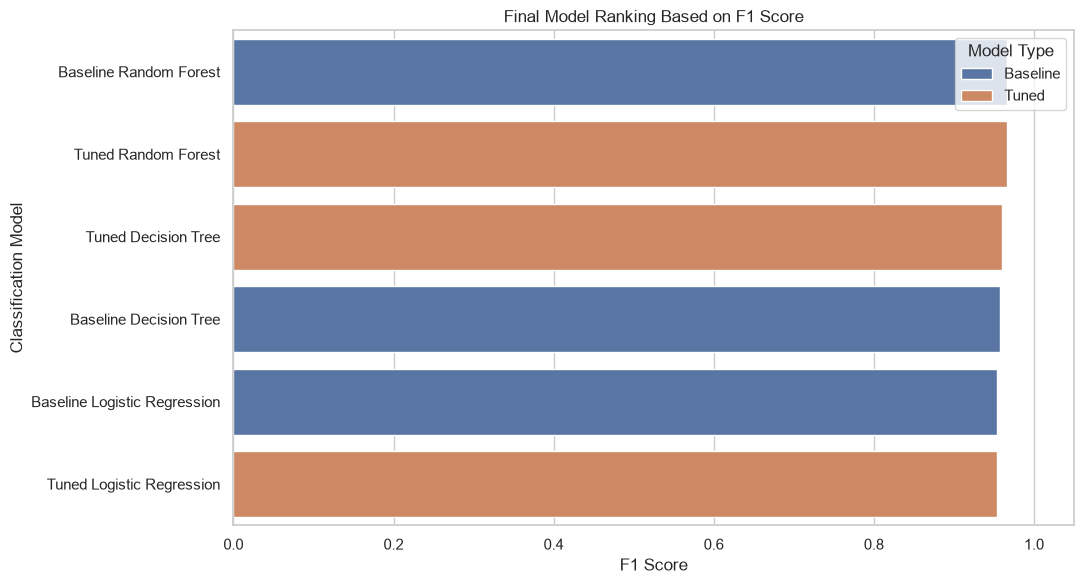

In [6]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=ranked_models,
    x="F1 Score",
    y="Model Name",
    hue="Model Type"
)

plt.title("Final Model Ranking Based on F1 Score")

plt.xlabel("F1 Score")
plt.ylabel("Classification Model")

plt.xlim(0, 1.05)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "final_model_ranking.png",
    dpi=300
)

plt.show()

In [7]:
best_model_info = ranked_models.iloc[0]

best_model_name = best_model_info["Model"]
best_model_type = best_model_info["Model Type"]

print("=" * 50)
print("BEST MODEL SELECTED")
print("=" * 50)

print("Model:", best_model_name)
print("Model Type:", best_model_type)

print("Validation Accuracy:",
      round(best_model_info["Accuracy"], 4))

print("Validation Precision:",
      round(best_model_info["Precision"], 4))

print("Validation Recall:",
      round(best_model_info["Recall"], 4))

print("Validation F1 Score:",
      round(best_model_info["F1 Score"], 4))

print("False Negatives:",
      best_model_info["False Negative"])

BEST MODEL SELECTED
Model: Random Forest
Model Type: Baseline
Validation Accuracy: 0.9537
Validation Precision: 0.9572
Validation Recall: 0.9757
Validation F1 Score: 0.9663
False Negatives: 580


In [8]:
model_filename = (
    best_model_name.lower().replace(" ", "_")
    + ".pkl"
)

if best_model_type == "Tuned":

    model_filename = "tuned_" + model_filename

selected_model = joblib.load(
    MODEL_DIR / model_filename
)

print("Selected Model File:", model_filename)

print("\nModel loaded successfully!")

Selected Model File: random_forest.pkl

Model loaded successfully!


In [9]:
classifier = selected_model.named_steps[
    "classifier"
]

print("Selected Classifier:")

print(classifier)

print("\nHyperparameters:")

for parameter, value in classifier.get_params().items():

    print(f"{parameter}: {value}")

Selected Classifier:
RandomForestClassifier(n_jobs=-1, random_state=42)

Hyperparameters:
bootstrap: True
ccp_alpha: 0.0
class_weight: None
criterion: gini
max_depth: None
max_features: sqrt
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 2
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 100
n_jobs: -1
oob_score: False
random_state: 42
verbose: 0
warm_start: False


In [10]:
X_train = pd.read_csv(
    DATA_DIR / "X_train.csv"
)

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
)["label"]

X_val = pd.read_csv(
    DATA_DIR / "X_val.csv"
)

y_val = pd.read_csv(
    DATA_DIR / "y_val.csv"
)["label"]

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)

Training Data: (140274, 42)
Validation Data: (35067, 42)


In [11]:
X_final_train = pd.concat(
    [X_train, X_val],
    ignore_index=True
)

y_final_train = pd.concat(
    [y_train, y_val],
    ignore_index=True
)

print("Final Training Features:",
      X_final_train.shape)

print("Final Training Target:",
      y_final_train.shape)

print("\nClass Distribution:")

print(y_final_train.value_counts())

Final Training Features: (175341, 42)
Final Training Target: (175341,)

Class Distribution:
label
1    119341
0     56000
Name: count, dtype: int64


In [12]:
final_model = clone(selected_model)

print("Training final model...", flush=True)

start_time = time.perf_counter()

final_model.fit(
    X_final_train,
    y_final_train
)

final_training_time = (
    time.perf_counter() - start_time
)

print("Final model trained successfully!")

print(
    f"Training Time: "
    f"{final_training_time:.2f} seconds"
)

Training final model...
Final model trained successfully!
Training Time: 175.56 seconds


In [13]:
X_test = pd.read_csv(
    DATA_DIR / "X_test.csv"
)

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
)["label"]

assert X_final_train.columns.equals(
    X_test.columns
)

assert len(X_test) == len(y_test)

print("Testing Features:", X_test.shape)

print("Testing Target:", y_test.shape)

print("\nTesting Class Distribution:")

print(y_test.value_counts())

Testing Features: (82332, 42)
Testing Target: (82332,)

Testing Class Distribution:
label
1    45332
0    37000
Name: count, dtype: int64


In [14]:
train_hashes = pd.util.hash_pandas_object(
    X_final_train,
    index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test,
    index=False
)

overlap_mask = test_hashes.isin(
    train_hashes
)

overlap_count = int(overlap_mask.sum())

print("Overlapping Test Records:",
      overlap_count)

print("Non-overlapping Test Records:",
      len(X_test) - overlap_count)

print(
    "Overlap Percentage:",
    round(overlap_count / len(X_test) * 100, 4)
)

Overlapping Test Records: 8541
Non-overlapping Test Records: 73791
Overlap Percentage: 10.3739


In [16]:
final_results = evaluate_classifier(
    final_model,
    X_test,
    y_test
)

final_results["Model"] = best_model_name

final_results["Model Type"] = best_model_type

final_performance_df = pd.DataFrame([
    final_results
])

display(final_performance_df.T)

print("=" * 50)
print("FINAL TEST PERFORMANCE")
print("=" * 50)

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC",
    "False Negative Rate",
    "False Positive Rate"
]:

    print(
        f"{metric}: "
        f"{final_results[metric] * 100:.2f}%"
    )

,0
Accuracy,0.872213
Precision,0.81887
Recall,0.986014
F1 Score,0.894703
ROC AUC,0.978607
True Negative,27113
False Positive,9887
False Negative,634
True Positive,44698
False Negative Rate,0.013986


FINAL TEST PERFORMANCE
Accuracy: 87.22%
Precision: 81.89%
Recall: 98.60%
F1 Score: 89.47%
ROC AUC: 97.86%
False Negative Rate: 1.40%
False Positive Rate: 26.72%


In [17]:
start_time = time.perf_counter()

y_test_pred = final_model.predict(X_test)

prediction_time = (
    time.perf_counter() - start_time
)

y_test_prob = final_model.predict_proba(
    X_test
)[:, 1]

print("Total Predictions:", len(y_test_pred))

print(
    f"Prediction Time: "
    f"{prediction_time:.4f} seconds"
)

print(
    f"Records Per Second: "
    f"{len(X_test) / prediction_time:.2f}"
)

Total Predictions: 82332
Prediction Time: 1.4461 seconds
Records Per Second: 56935.35


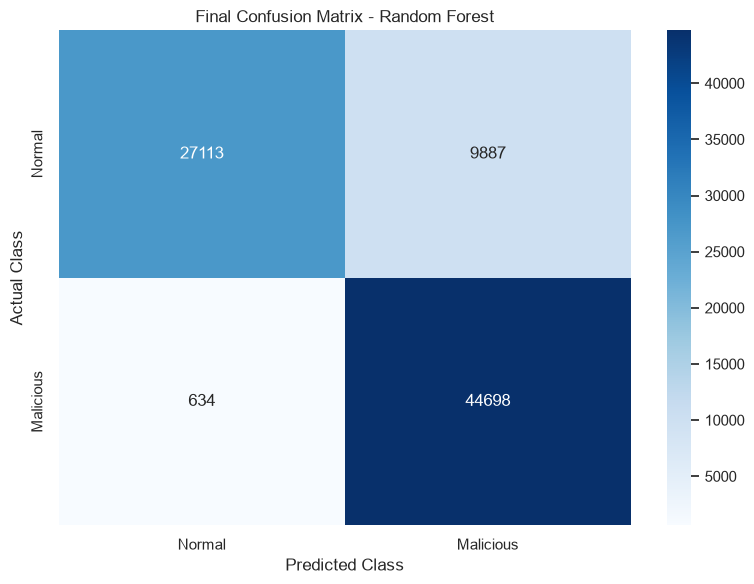

In [18]:
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Malicious"],
    yticklabels=["Normal", "Malicious"]
)

plt.title(
    f"Final Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "final_confusion_matrix.png",
    dpi=300
)

plt.show()

In [19]:
tn, fp, fn, tp = cm.ravel()

total_attacks = tp + fn

print("Total Actual Attacks:", total_attacks)

print("Successfully Detected Attacks:", tp)

print("Missed Attacks:", fn)

print("False Alarms:", fp)

print("Correctly Identified Normal Traffic:", tn)

print(
    f"\nAttack Detection Rate: "
    f"{tp / total_attacks * 100:.2f}%"
)

print(
    f"Attack Miss Rate: "
    f"{fn / total_attacks * 100:.2f}%"
)

Total Actual Attacks: 45332
Successfully Detected Attacks: 44698
Missed Attacks: 634
False Alarms: 9887
Correctly Identified Normal Traffic: 27113

Attack Detection Rate: 98.60%
Attack Miss Rate: 1.40%


In [20]:
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=[
        "Normal Traffic",
        "Malicious Traffic"
    ],
    zero_division=0
))

final_report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=[
        "Normal Traffic",
        "Malicious Traffic"
    ],
    output_dict=True,
    zero_division=0
)

final_report_df = pd.DataFrame(
    final_report
).T

display(final_report_df.round(4))

                   precision    recall  f1-score   support

   Normal Traffic       0.98      0.73      0.84     37000
Malicious Traffic       0.82      0.99      0.89     45332

         accuracy                           0.87     82332
        macro avg       0.90      0.86      0.87     82332
     weighted avg       0.89      0.87      0.87     82332



,precision,recall,f1-score,support
Normal Traffic,0.9772,0.7328,0.8375,37000.0000
Malicious Traffic,0.8189,0.9860,0.8947,45332.0000
accuracy,0.8722,0.8722,0.8722,0.8722
macro avg,0.8980,0.8594,0.8661,82332.0000
weighted avg,0.8900,0.8722,0.8690,82332.0000


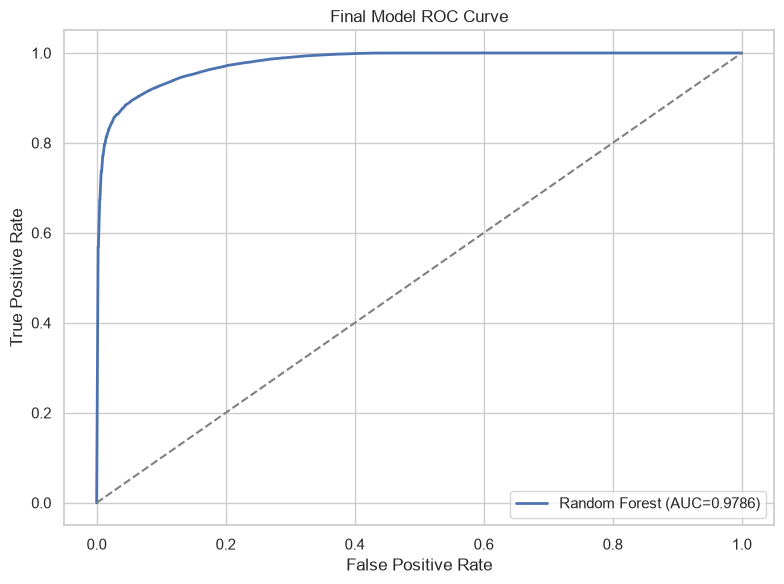

In [21]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_test_prob
)

auc_score = roc_auc_score(
    y_test,
    y_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{best_model_name} (AUC={auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("Final Model ROC Curve")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "final_roc_curve.png",
    dpi=300
)

plt.show()

In [22]:
non_overlap_mask = ~overlap_mask

X_unique_test = X_test.loc[
    non_overlap_mask
]

y_unique_test = y_test.loc[
    non_overlap_mask
]

if len(X_unique_test) > 0 and y_unique_test.nunique() == 2:

    unique_results = evaluate_classifier(
        final_model,
        X_unique_test,
        y_unique_test
    )

    unique_performance_df = pd.DataFrame([
        unique_results
    ])

    display(unique_performance_df.round(4))

    unique_performance_df.to_csv(
        RESULT_DIR / "non_overlap_test_performance.csv",
        index=False
    )

else:

    print("Insufficient records for separate evaluation.")

,Accuracy,Precision,Recall,F1 Score,ROC AUC,True Negative,False Positive,False Negative,True Positive,False Negative Rate,False Positive Rate
0,0.8638,0.7997,0.9839,0.8823,0.9765,26097,9431,616,37647,0.0161,0.2655


,Metric,Validation,Final Test
0,Accuracy,0.9537,0.8722
1,Precision,0.9572,0.8189
2,Recall,0.9757,0.9860
3,F1 Score,0.9663,0.8947
4,ROC AUC,0.9928,0.9786


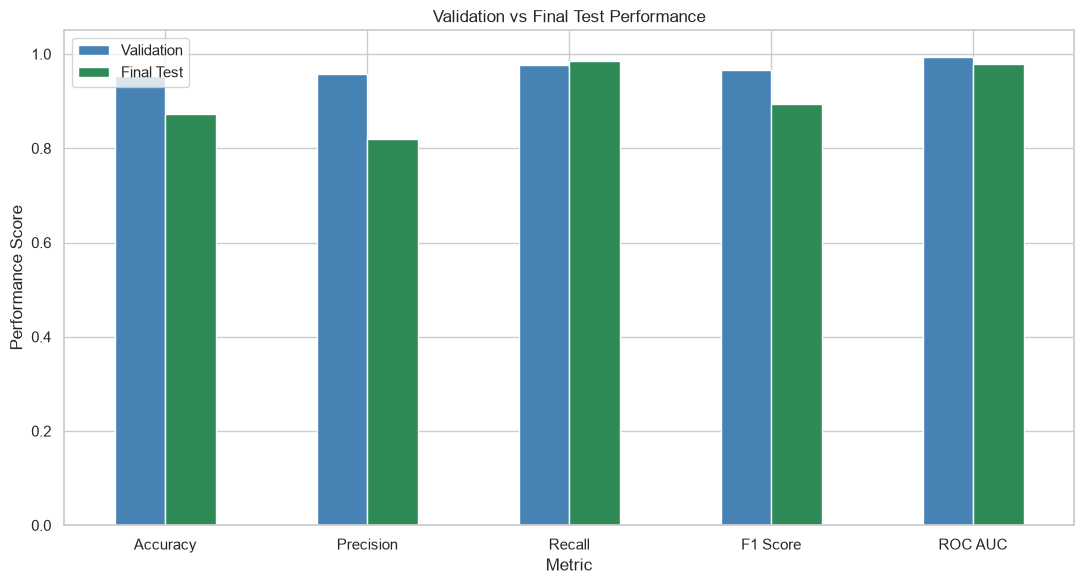

In [24]:
comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

final_comparison_df = pd.DataFrame({

    "Metric": comparison_metrics,

    "Validation": [
        best_model_info[m]
        for m in comparison_metrics
    ],

    "Final Test": [
        final_results[m]
        for m in comparison_metrics
    ]
})

display(final_comparison_df.round(4))

final_comparison_df.set_index("Metric").plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "seagreen"]
)

plt.title("Validation vs Final Test Performance")

plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "validation_vs_test.png",
    dpi=300
)

plt.show()

In [25]:
final_model_path = (
    MODEL_DIR / "best_model_pipeline.pkl"
)

joblib.dump(
    final_model,
    final_model_path,
    compress=3
)

print("Final model saved successfully!")

print("Model Path:", final_model_path)

print(
    "Model Size:",
    round(
        final_model_path.stat().st_size / (1024 ** 2),
        2
    ),
    "MB"
)

Final model saved successfully!
Model Path: ..\models\best_model_pipeline.pkl
Model Size: 19.66 MB


In [26]:
metadata = {

    "project_name":
        "Network Intrusion Detection System",

    "dataset":
        "UNSW-NB15",

    "model_name":
        best_model_name,

    "model_type":
        best_model_type,

    "selection_metric":
        "Validation F1 Score",

    "total_features":
        int(X_final_train.shape[1]),

    "feature_names":
        X_final_train.columns.tolist(),

    "numerical_features":
        X_final_train.select_dtypes(
            include=np.number
        ).columns.tolist(),

    "categorical_features":
        X_final_train.select_dtypes(
            include=["object", "category"]
        ).columns.tolist(),

    "training_records":
        int(len(X_final_train)),

    "testing_records":
        int(len(X_test)),

    "overlapping_test_records":
        overlap_count,

    "accuracy":
        float(final_results["Accuracy"]),

    "precision":
        float(final_results["Precision"]),

    "recall":
        float(final_results["Recall"]),

    "f1_score":
        float(final_results["F1 Score"]),

    "roc_auc":
        float(final_results["ROC AUC"]),

    "false_negatives":
        int(fn),

    "false_positives":
        int(fp),

    "training_time_seconds":
        float(final_training_time),

    "sklearn_version":
        sklearn.__version__,

    "class_labels": {
        "0": "Normal",
        "1": "Malicious"
    }
}

with open(
    RESULT_DIR / "final_model_metadata.json",
    "w"
) as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

print("Model metadata saved successfully!")

Model metadata saved successfully!


C:\Users\ANUBHAB GHOSH\AppData\Local\Temp\ipykernel_23496\408545758.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_final_train.select_dtypes(


In [27]:
ranked_models.to_csv(
    RESULT_DIR / "final_model_ranking.csv",
    index=False
)

final_performance_df.to_csv(
    RESULT_DIR / "final_model_performance.csv",
    index=False
)

final_report_df.to_csv(
    RESULT_DIR / "final_classification_report.csv"
)

final_comparison_df.to_csv(
    RESULT_DIR / "validation_vs_test.csv",
    index=False
)

prediction_df = pd.DataFrame({

    "Actual Label": y_test.values,

    "Predicted Label": y_test_pred,

    "Malicious Probability": y_test_prob

})

prediction_df.to_csv(
    RESULT_DIR / "final_test_predictions.csv",
    index=False
)

print("All final reports saved successfully!")

All final reports saved successfully!


In [28]:
loaded_model = joblib.load(
    MODEL_DIR / "best_model_pipeline.pkl"
)

sample = X_test.head(10)

original_predictions = final_model.predict(
    sample
)

loaded_predictions = loaded_model.predict(
    sample
)

assert np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Saved model verified successfully!")

print("Model is ready for unseen data prediction!")

Saved model verified successfully!
Model is ready for unseen data prediction!
